**Purpose:** Imports libraries for morphological image processing and visualization.

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

**Purpose:** Defines erosion using a structuring element.

In [25]:
def erosion(img,kernel):
    result = np.zeros_like(img)
    
    rows,cols = img.shape
    kr , kc = kernel.shape
    
    pad_x =kr//2
    pad_y = kc//2
    
    for i in range(pad_x,rows-pad_x):
        for j in range(pad_y,cols- pad_y):
            region = img[i-pad_x:i+pad_x+1, j-pad_y:j+pad_y+1]
            
            if np.all(region[kernel==1] == 255):
                result[i][j] = 255
                
    return result

**Purpose:** Defines dilation using a structuring element.

In [26]:
def dilation (img,kernel):
    result = np.zeros_like(img)
    rows, cols = img.shape
    kr, kc = kernel.shape
    
    pad_x = kr//2
    pad_y = kc//2
    
    for i in range(pad_x, rows-pad_x):
        for j in range(pad_y,cols-pad_y):
            region = img[i-pad_x:i+pad_x+1,j-pad_y:j+pad_y+1]
            
            if np.any(region[kernel==1] == 255):
                result[i,j] = 255
    
    return result

**Purpose:** Extracts object boundaries by subtracting the eroded image.

In [27]:
def boundary_extraction(img,kernel):
    erased = erosion(img,kernel)
    return img - erased

**Purpose:** Defines hit-or-miss matching for foreground and background patterns.

In [28]:
def hit_or_miss(img,hit, miss):
    erased = erosion(img, hit)
    
    bg = 255 - img
    missed = erosion(bg,miss)
    
    result = np.zeros_like(img)
    
    result[(erased==255) & (missed==255)] = 255
    
    return result

**Purpose:** Defines an iterative thinning operation using hit-or-miss results.

In [31]:
def thinning(img,kernel):
    result = img.copy()
    
    
    
    while True:
        hit_miss = hit_or_miss(img,kernel,kernel)
        
        new_res = result-hit_miss
        
        if np.array_equal(result, new_res):
            break
        
        result = new_res
    
    return result

**Purpose:** Binarizes the image, runs boundary, hit-or-miss, and thinning operations, and displays them.

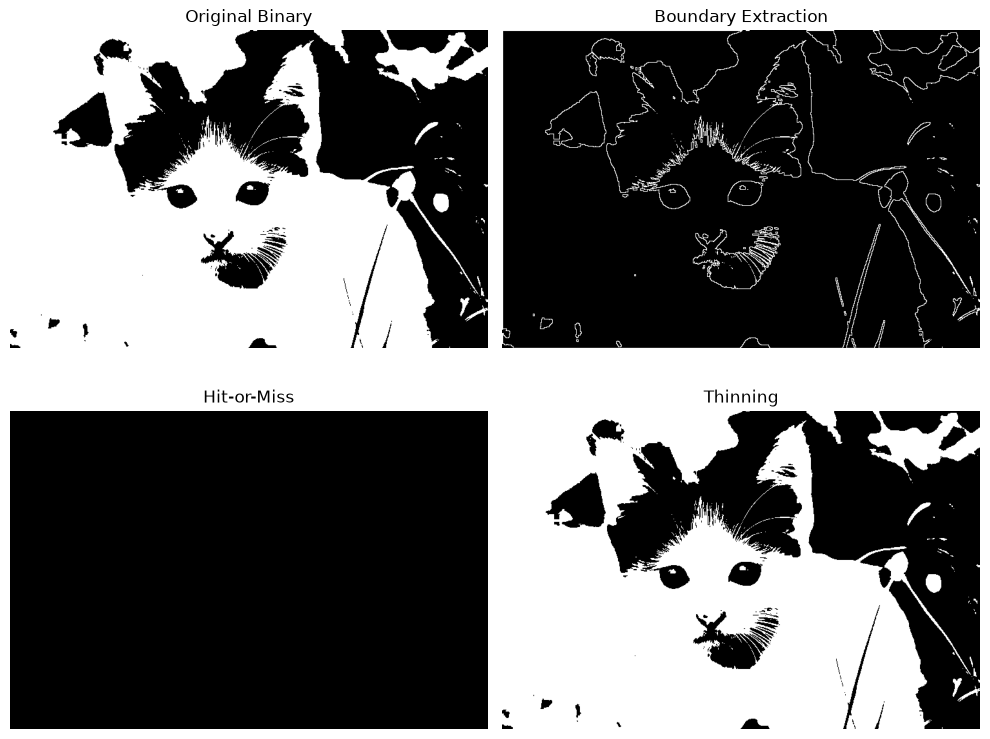

In [32]:
img = cv2.imread("../cat.jpg", 0)

if img is None:
    print("Image not found!")
    exit()

# Convert image to binary
binary = np.where(img >= 127, 255, 0).astype(np.uint8)

# Define structuring elements
kernel = np.ones((3, 3), dtype=np.uint8)

hit = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

miss = np.array([
    [1, 0, 1],
    [0, 0, 0],
    [1, 0, 1]
], dtype=np.uint8)


# Apply operations
boundary = boundary_extraction(binary, kernel)

hitmiss = hit_or_miss(binary, hit, miss)

thin = thinning(binary, kernel)


# Display results
images = [
    binary,
    boundary,
    hitmiss,
    thin
]

titles = [
    "Original Binary",
    "Boundary Extraction",
    "Hit-or-Miss",
    "Thinning"
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.